# Dark Store Performance Analysis: India
**Question:** A quick-commerce company runs 52 dark stores across 8 Indian metros. Why do some cities and stores
miss the 10-minute delivery promise far more often than others, what does it cost, and what should operations
fix first?

This notebook walks through the analysis. The heavy lifting lives in SQL (`sql/`) and `src/`; here we query the
cleaned DuckDB warehouse and read the results.

> **Data note:** real dark-store data is not public, so the data comes from `src/generate_data.py`, an operational
> simulation where delivery time = picking + rider wait + travel, with city-specific traffic, weather and
> festivals. See the README for details.

In [1]:
import json
from pathlib import Path
import duckdb, pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(ROOT / "data" / "darkstore.duckdb"), read_only=True)
P, FIG = ROOT / "data" / "processed", ROOT / "reports" / "figures"
m = json.loads((ROOT / "reports" / "metrics.json").read_text())
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
q = lambda sql: con.execute(sql).df()

## 1. Data and cleaning
The raw export has the usual problems. `sql/00_staging.sql` fixes them and logs what it changed:

In [2]:
q("SELECT * FROM data_quality_log")

,check_name,rows_affected
0,Duplicate order rows removed,1546
1,Store IDs with bad casing/whitespace fixed,2323
2,Payment method labels standardised,3120
3,Delivered orders with impossible timings (excl...,248
4,Missing distances imputed from coordinates,1159
5,"Orders not rated by customer (expected, left a...",167740


In [3]:
q("SELECT table_name, estimated_size AS rows FROM duckdb_tables() ORDER BY 1")

,table_name,rows
0,data_quality_log,6
1,dim_city,8
2,dim_customer,87000
3,dim_date,181
4,dim_product,60
5,dim_store,52
6,dim_weather_hour,34752
7,fact_order_items,1364935
8,fact_orders,386593
9,fact_rider_shifts,225888


## 2. Cities
`sql/02_city_scorecard.sql`. Mumbai misses the promise about twice as often as Chennai.

In [4]:
pd.read_csv(P / "city_scorecard.csv")[["city_name","stores","orders","avg_delivery_min","late_pct","cancel_pct","avg_rating","avg_distance_km","avg_travel_min","avg_rider_wait_min"]]

,city_name,stores,orders,avg_delivery_min,late_pct,cancel_pct,avg_rating,avg_distance_km,avg_travel_min,avg_rider_wait_min
0,Chennai,5,36665,10.28,18.1,3.73,4.38,2.05,5.69,1.86
1,Ahmedabad,3,14318,10.69,20.2,4.10,4.32,2.13,5.63,2.34
2,Hyderabad,6,39757,11.75,25.1,3.85,4.28,2.38,6.79,2.21
3,Bengaluru,12,115015,11.43,25.9,3.45,4.26,2.08,6.68,1.83
4,Kolkata,4,20873,11.88,26.9,3.99,4.24,2.29,7.16,2.01
5,Pune,5,29184,11.96,27.0,3.84,4.22,2.42,7.22,1.99
6,Delhi NCR,9,70215,12.23,28.5,3.34,4.21,2.60,7.81,1.62
7,Mumbai,8,60566,13.10,37.5,3.17,4.09,2.46,8.48,1.60


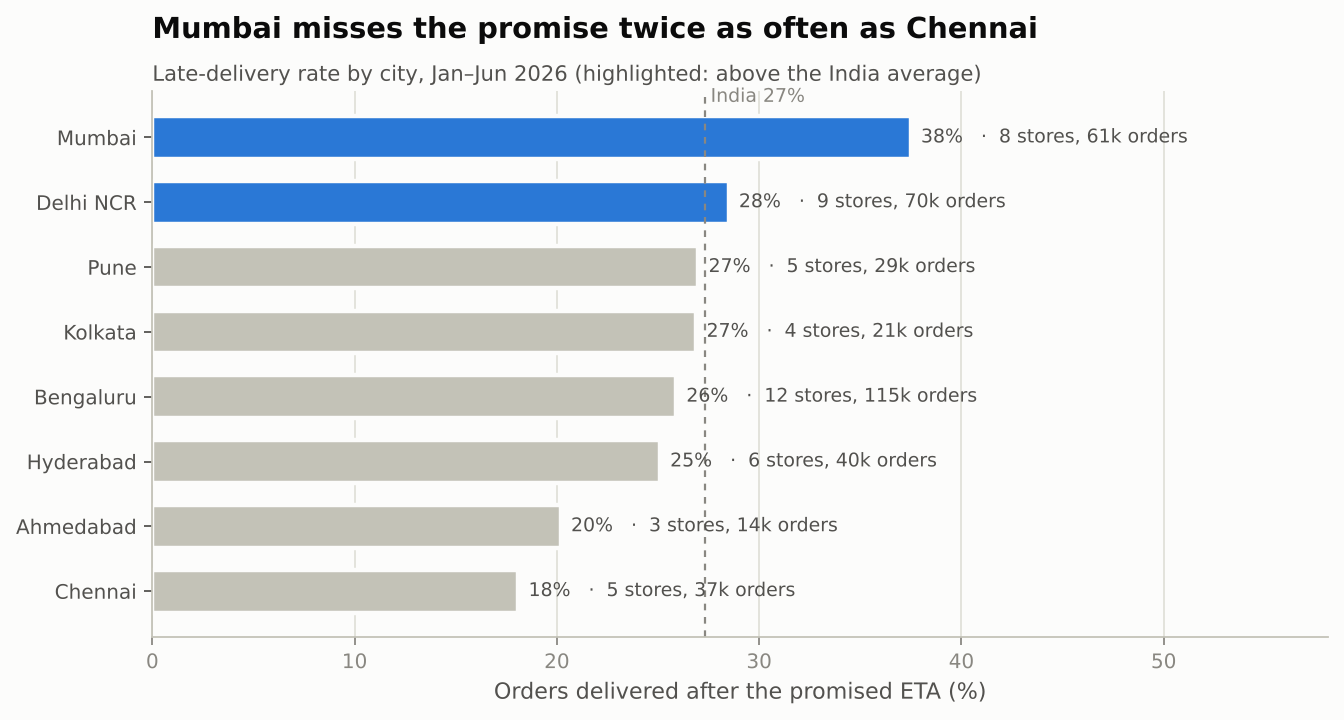

In [5]:
Image(FIG / "01_city_late_rate.png", width=760)

### Each city has its own seasons
Weekly late rate per city against India (`sql/08_weekly_city_trend.sql`). Mumbai jumps when the monsoon arrives in
June; Delhi is worst in foggy January; Kolkata climbs with the April–May nor'westers.

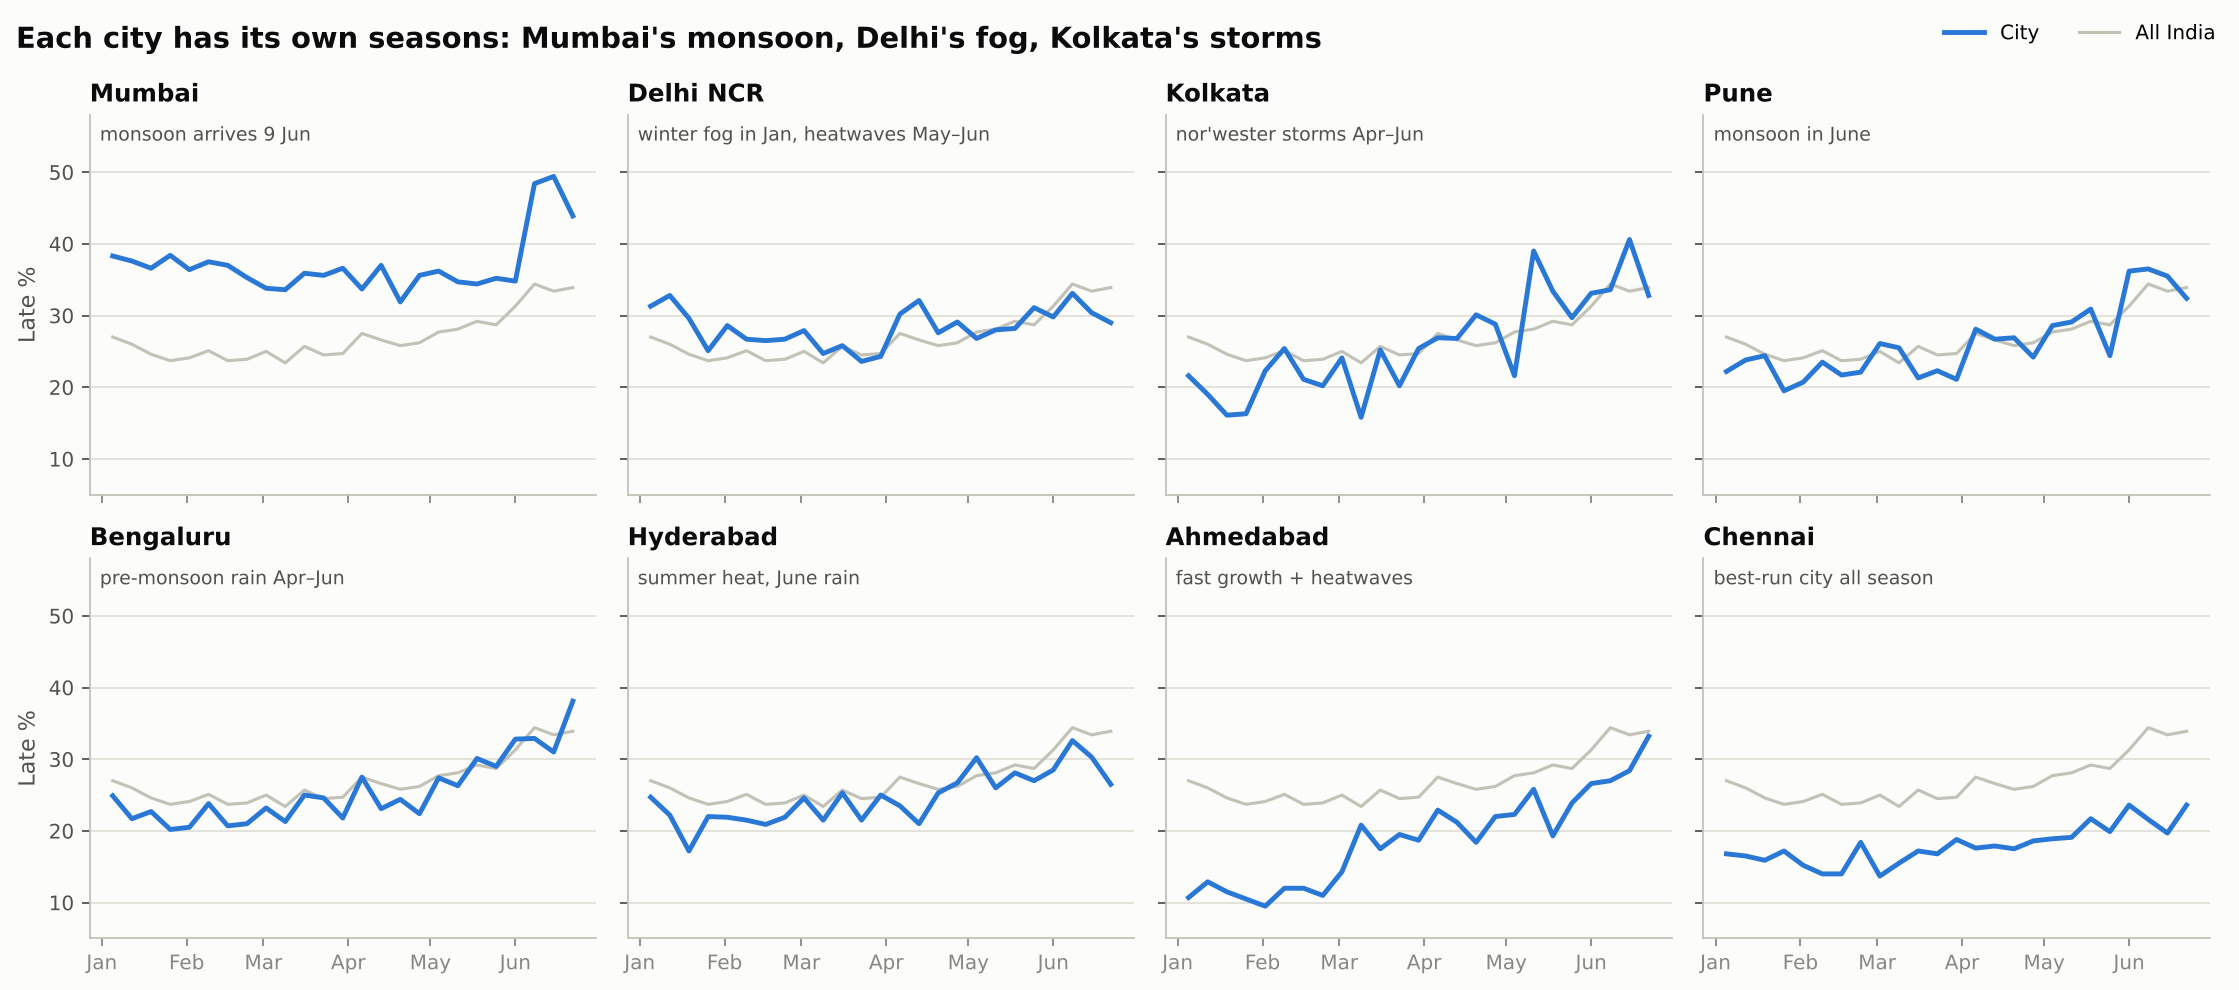

In [6]:
Image(FIG / "02_city_weekly_trend.png", width=1000)

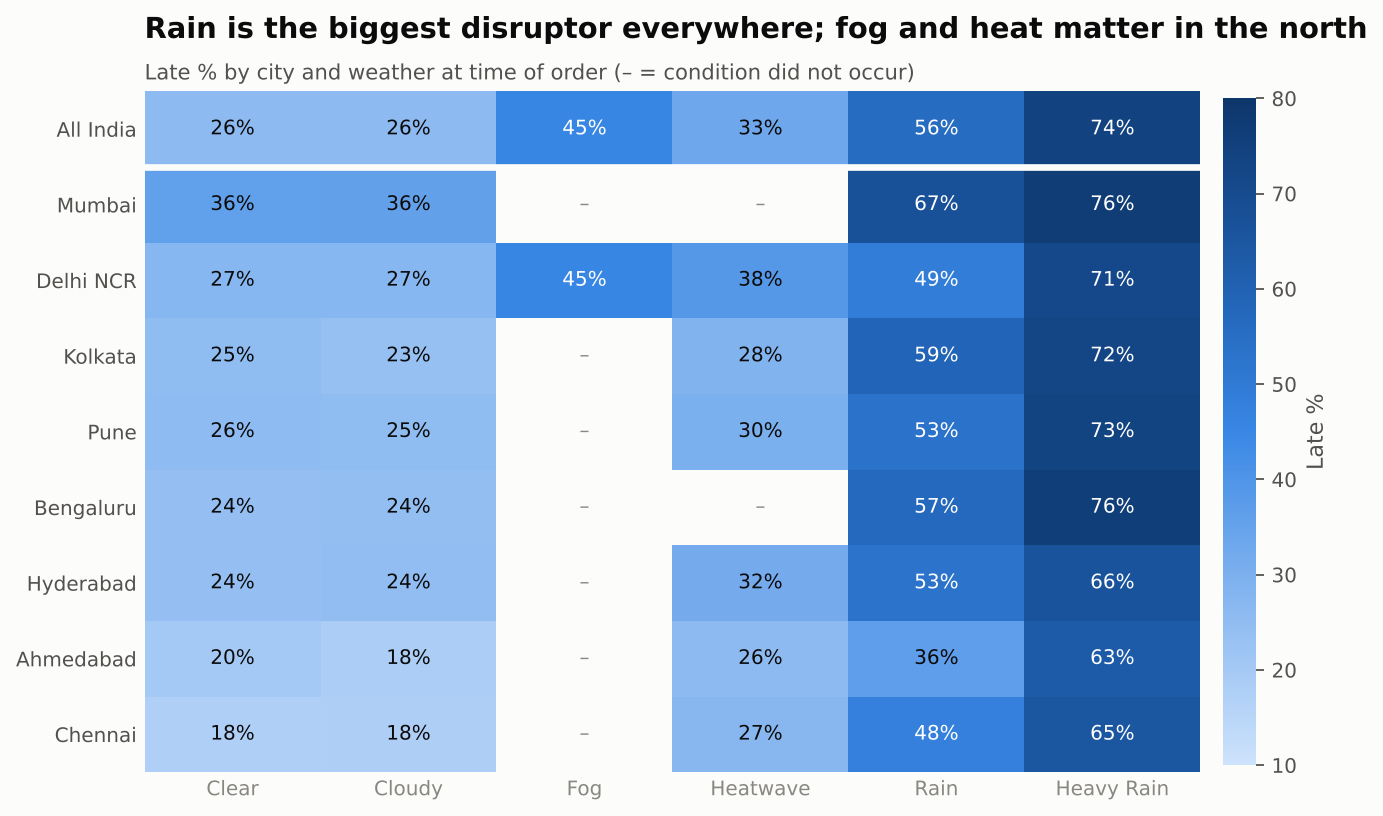

In [7]:
Image(FIG / "03_weather_by_city.png", width=760)

## 3. Stores: where does each one lose time?
`sql/04_delivery_time_breakdown.sql` splits delivery into picking, rider wait and travel, and names the stage furthest above the India average. Travel is judged on distance, not on the city's traffic.

In [8]:
b = pd.read_csv(P / "delivery_time_breakdown.csv")
b[b.primary_bottleneck != "On par"]

,store_id,city_code,pick_min,rider_wait_min,travel_min,delivery_min,avg_distance_km,city_travel_min_per_km,pick_gap_vs_india,wait_gap_vs_india,distance_gap_vs_india,primary_bottleneck
0,MUM08,MUM,2.83,1.10,13.23,17.17,3.99,3.44,-0.02,-0.74,5.79,Long distances
1,KOL01,KOL,2.68,2.06,11.87,16.60,3.99,3.12,-0.17,0.22,5.26,Long distances
2,DEL06,DEL,2.81,1.53,10.27,14.61,3.50,3.00,-0.04,-0.31,3.60,Long distances
3,PUN05,PUN,2.77,1.58,9.89,14.23,3.44,2.98,-0.08,-0.26,3.39,Long distances
4,MUM02,MUM,2.85,1.41,9.90,14.16,2.92,3.44,-0.00,-0.43,2.11,Long distances
5,BLR07,BLR,2.80,3.29,8.02,14.11,2.56,3.20,-0.05,1.45,0.81,Rider shortage
6,DEL09,DEL,2.83,1.55,9.45,13.83,3.22,3.00,-0.02,-0.29,2.76,Long distances
7,BLR04,BLR,2.81,1.19,9.28,13.28,3.01,3.20,-0.04,-0.64,2.27,Long distances
9,DEL03,DEL,2.80,1.58,8.75,13.13,2.96,3.00,-0.05,-0.25,1.97,Long distances
11,HYD05,HYD,2.75,1.99,8.10,12.84,2.91,2.84,-0.10,0.16,1.72,Long distances


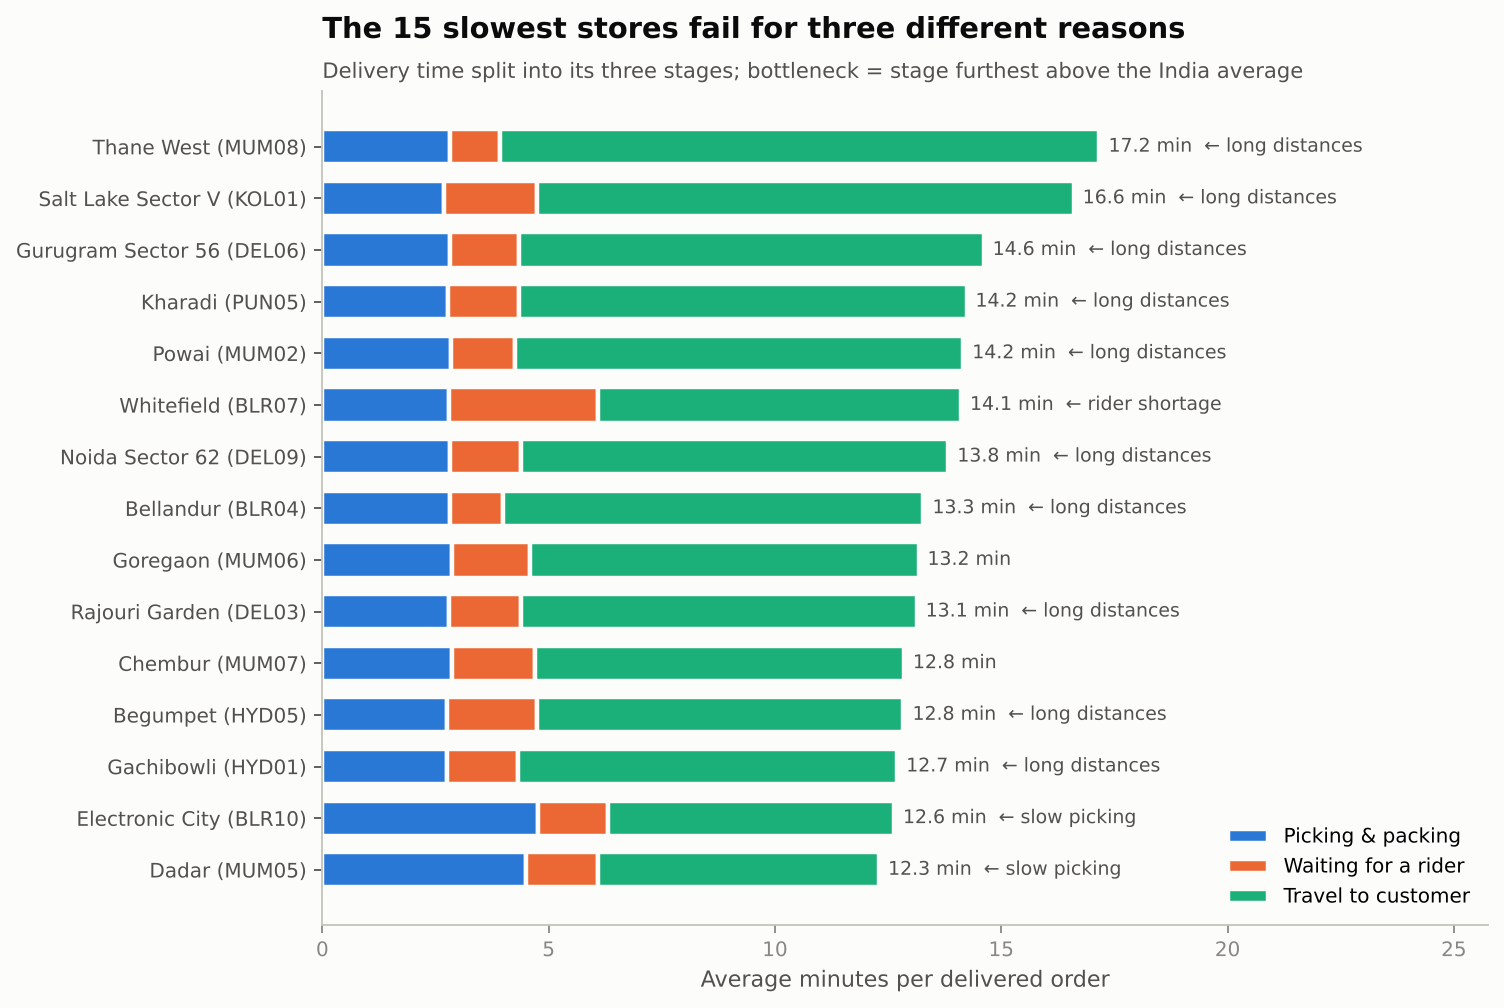

In [9]:
Image(FIG / "04_store_bottlenecks.png", width=820)

## 4. What drives lateness?
`sql/05_late_drivers.sql`, all India:

In [10]:
d = pd.read_csv(P / "late_drivers.csv")
d[d.city_code == "IN"]

,city_code,driver,level,orders,late_pct,avg_delivery_min
90,IN,Distance,0-1 km,84931,12.4,7.43
91,IN,Distance,1-2 km,130078,20.7,9.53
92,IN,Distance,2-3 km,57717,28.4,12.28
93,IN,Distance,3-4 km,38057,28.2,15.14
94,IN,Distance,4+ km,61893,60.1,20.06
95,IN,Rider utilisation,1. <60%,117260,15.4,10.58
96,IN,Rider utilisation,2. 60-90%,76457,18.6,11.05
97,IN,Rider utilisation,3. 90-120%,105390,20.3,11.04
98,IN,Rider utilisation,4. >120%,73569,65.3,15.60
99,IN,Time of day,1. Morning (6-11),85214,32.4,12.39


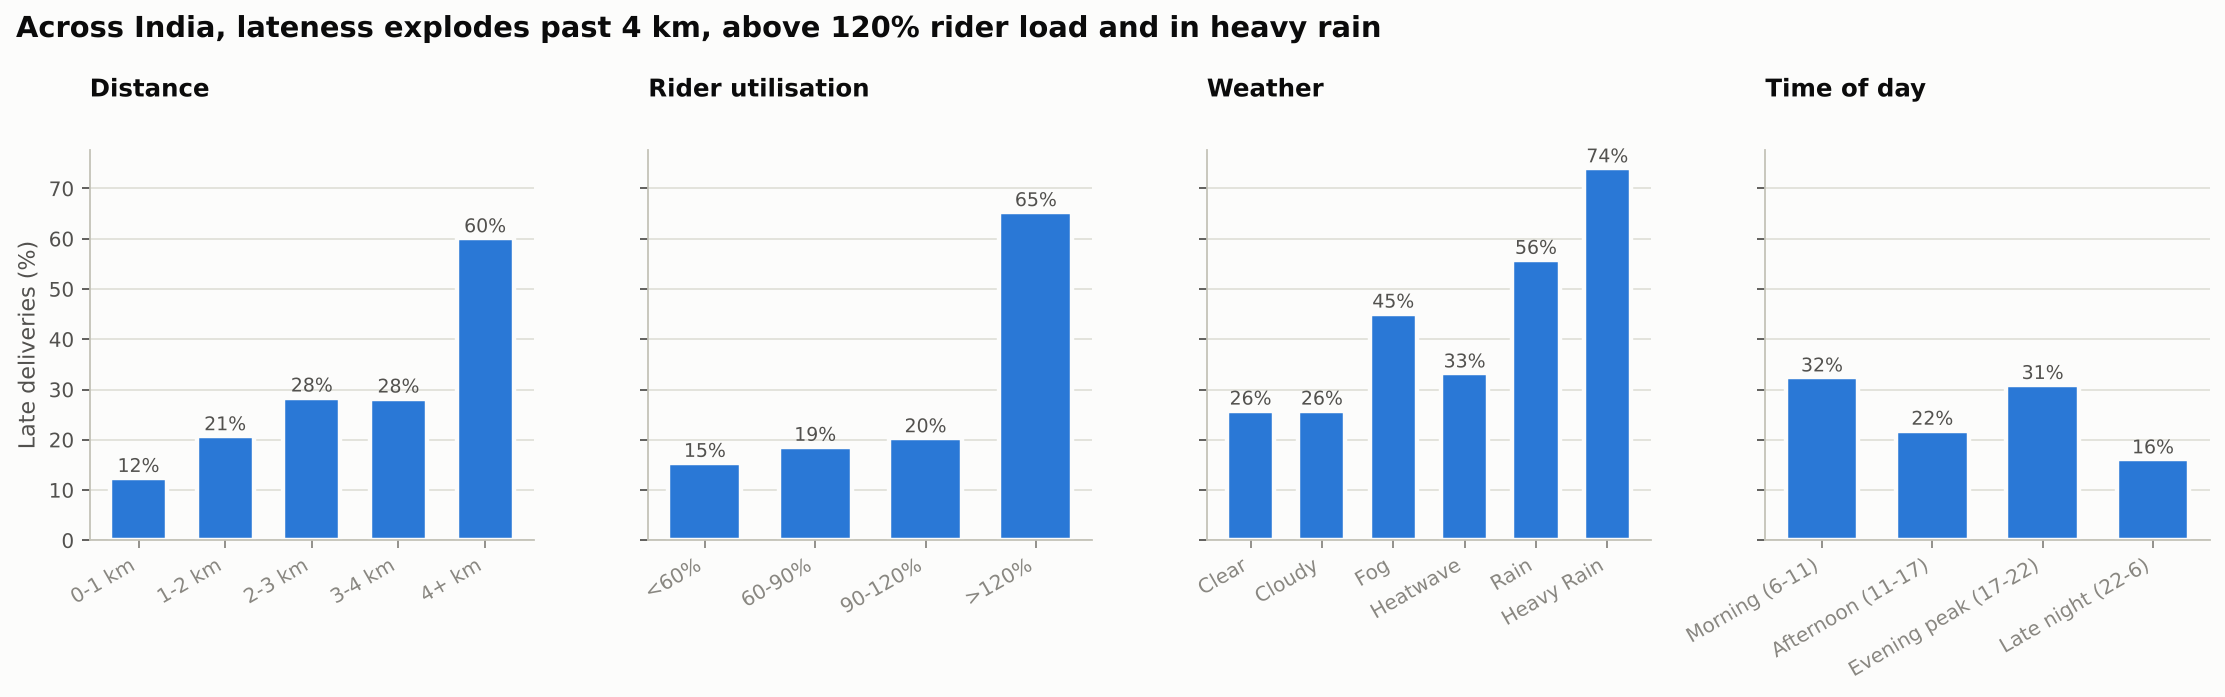

In [11]:
Image(FIG / "05_late_rate_drivers.png", width=1000)

### Regression: separating the effects
OLS of delivery time on distance (with a separate slope per city), weather, peak traffic, rider load, basket size
and store fixed effects.

In [12]:
c = pd.read_csv(P / "delivery_time_drivers_model.csv")
print(f"R² = {m['model_r2']}")
c[(c.group != "Store effect (vs BLR01, all else equal)") | (c.minutes_added.abs() > 0.5)]

R² = 0.858


,group,driver,minutes_added,ci_low,ci_high,p_value
0,Condition,Rain (vs clear),1.89,1.82,1.96,0.000000e+00
1,Condition,Heavy rain (vs clear),3.09,2.97,3.20,0.000000e+00
2,Condition,Fog (vs clear),1.84,1.70,1.99,1.100000e-137
3,Condition,Heatwave (vs clear),0.28,0.19,0.36,5.100000e-11
4,Condition,Peak traffic hour,1.89,1.88,1.91,0.000000e+00
5,Condition,Each +10 pts rider utilisation above 75%,0.69,0.68,0.69,0.000000e+00
6,Condition,Each extra item in the basket,0.41,0.40,0.41,0.000000e+00
7,Condition,Weekend,-0.10,-0.12,-0.09,2.200000e-41
19,"Store effect (vs BLR01, all else equal)",BLR10,1.93,1.87,1.99,0.000000e+00
50,"Store effect (vs BLR01, all else equal)",MUM05,1.69,1.62,1.76,0.000000e+00


Once distance, weather, traffic and rider load are controlled for, the only stores still slower than the rest
are Electronic City (BLR10) and Dadar (MUM05): their problem is inside the store.

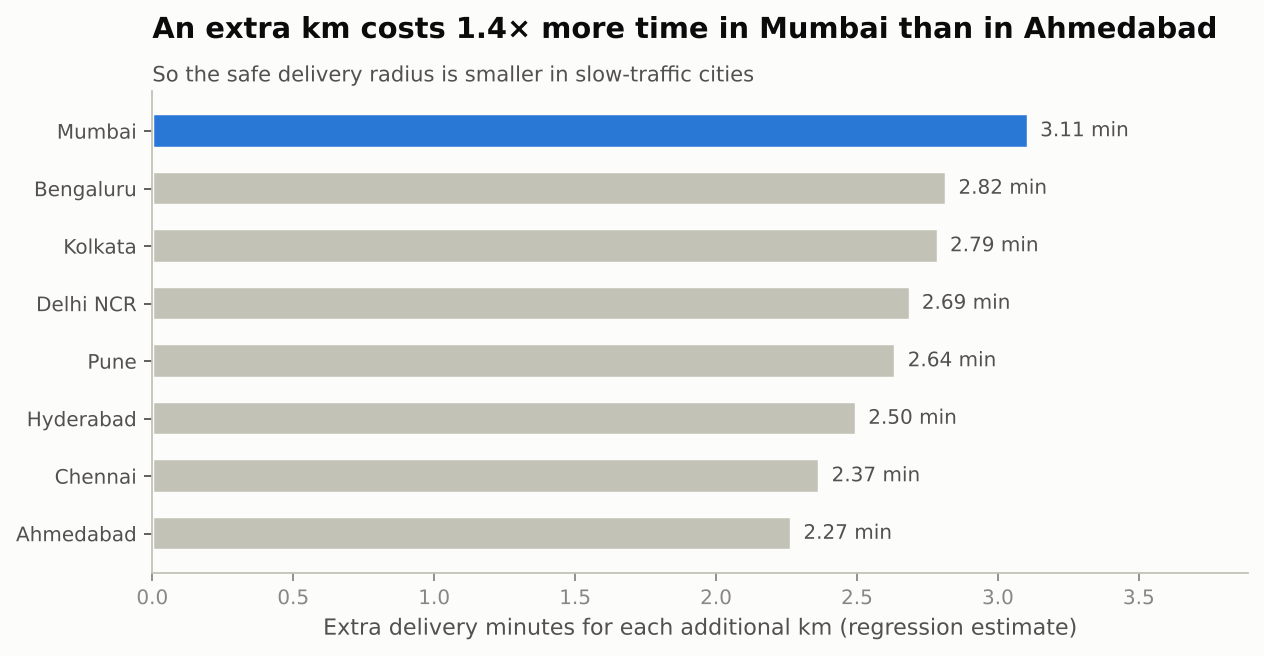

In [13]:
Image(FIG / "06_minutes_per_km_by_city.png", width=700)

### How far can a store really deliver in 10 minutes?

In [14]:
pd.read_csv(P / "promise_radius.csv")

,city_code,city_name,radius_10min_km,orders_within_radius_pct,travel_min_per_km
0,MUM,Mumbai,1.41,31.1,3.44
1,BLR,Bengaluru,1.60,43.4,3.20
2,HYD,Hyderabad,1.77,52.8,2.84
3,KOL,Kolkata,1.83,53.3,3.12
4,PUN,Pune,1.89,55.1,2.98
5,AMD,Ahmedabad,2.10,64.5,2.64
6,DEL,Delhi NCR,2.13,59.8,3.00
7,CHE,Chennai,2.49,73.2,2.77


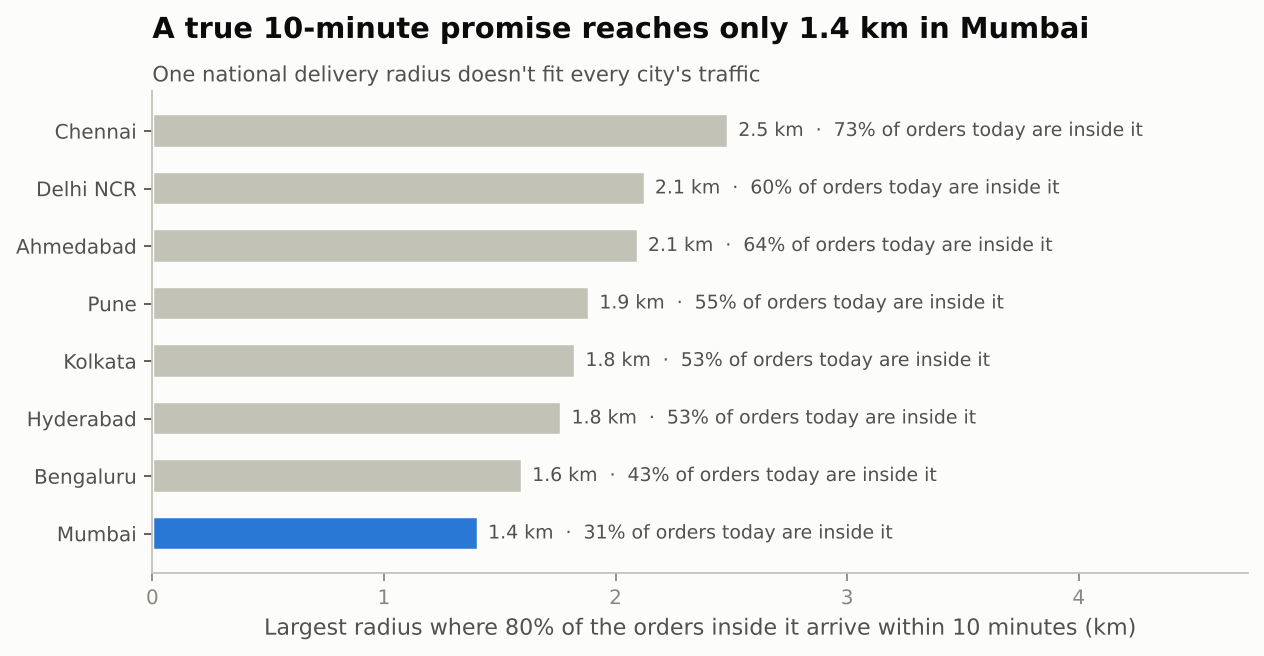

In [15]:
Image(FIG / "13_ten_minute_radius.png", width=700)

## 5. Catching incidents early
Each week, every store's late rate is compared with its own 8-week baseline. A plain version of that rule also
fires when a whole city slows down (Mumbai's monsoon), so the city's own swing is subtracted first, and the jump
must persist into a second week.

In [16]:
pd.read_csv(P / "naive_alerts.csv")

,store_id,city_code,week_start,late_pct,raw_jump_pts,jump_vs_city_pts
0,BLR03,BLR,2026-05-18,62.8,41.88,36.43
1,DEL06,DEL,2026-04-06,62.1,31.84,27.40
2,MUM02,MUM,2026-06-08,49.9,13.89,0.45
3,MUM03,MUM,2026-06-08,45.0,19.85,6.42
4,MUM05,MUM,2026-06-08,60.6,15.30,1.87
5,MUM06,MUM,2026-06-08,49.8,19.50,6.07
6,MUM07,MUM,2026-06-15,46.7,11.31,-1.64
7,MUM08,MUM,2026-06-08,60.1,11.24,-2.20
8,PUN05,PUN,2026-06-01,43.3,10.42,1.56


In [17]:
pd.DataFrame(m["incidents"])[["store_id","week_detected","status","riders_on_shift_before","riders_on_shift_during","rider_wait_min_before","rider_wait_min_during","late_pct_before","late_pct_during","root_cause"]]

,store_id,week_detected,status,riders_on_shift_before,riders_on_shift_during,rider_wait_min_before,rider_wait_min_during,late_pct_before,late_pct_during,root_cause
0,BLR03,2026-05-18,Ongoing,3.17,1.66,1.62,7.09,22.5,60.1,Fewer riders on shift
1,DEL06,2026-04-06,Resolved,3.59,1.39,1.04,7.45,28.9,65.5,Fewer riders on shift


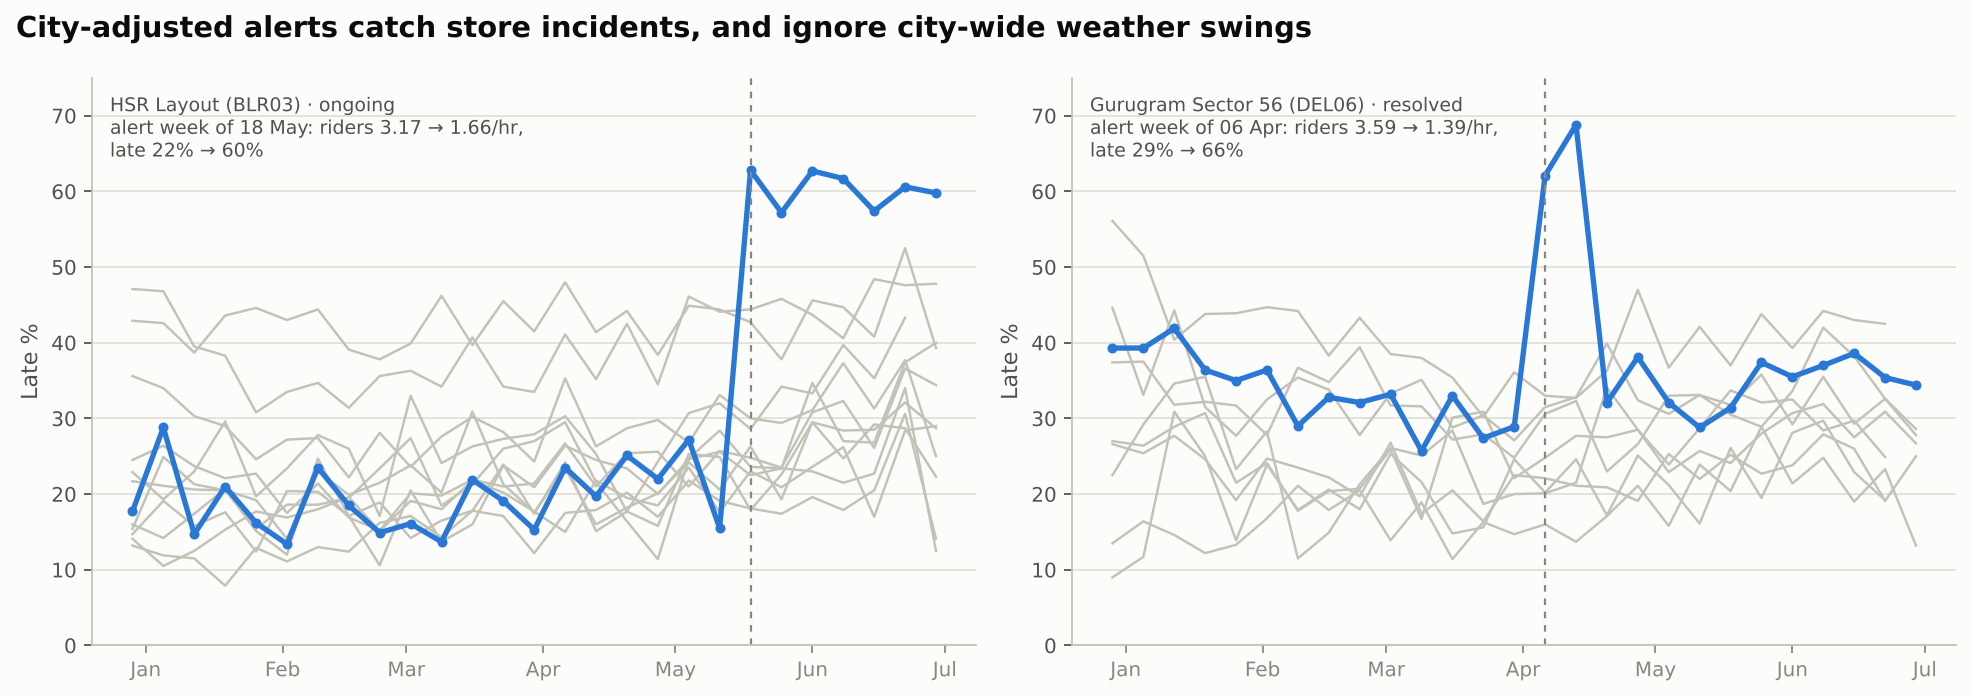

In [18]:
Image(FIG / "07_incident_detection.png", width=1000)

## 6. What lateness costs

In [19]:
r = pd.read_csv(P / "retention_first_order.csv")
r[r.city_code == "IN"]

,city_code,first_order_experience,customers,repeat_within_30d_pct,avg_orders_next_30d
20,IN,On time,16663,68.3,1.60
21,IN,Late by < 5 min,4763,61.5,1.38
22,IN,Late by 5+ min,1876,51.7,1.15
23,IN,Cancelled,876,61.9,1.48


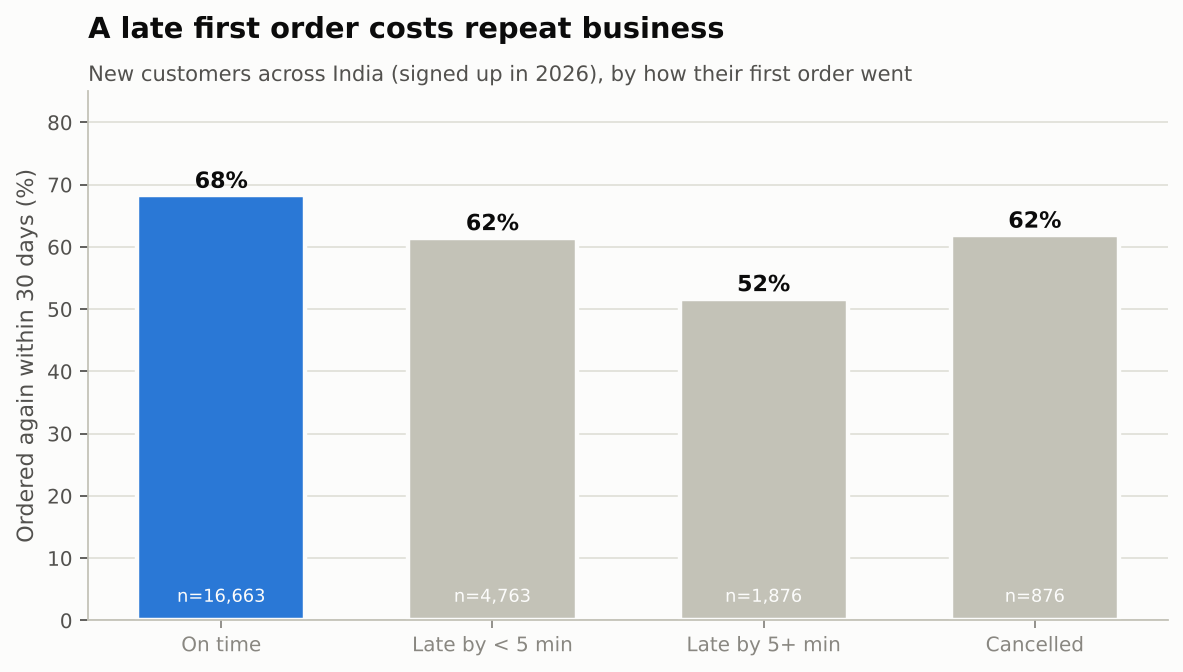

In [20]:
Image(FIG / "08_retention_after_first_order.png", width=640)

In [21]:
pd.read_csv(P / "rating_vs_lateness.csv")

,lateness,has_missing_items,rated_orders,avg_rating,bad_rating_pct
0,1. On time,False,136845,4.71,0.0
1,1. On time,True,12163,3.91,0.1
2,2. Late 0-3 min,False,28528,3.41,2.2
3,2. Late 0-3 min,True,2517,2.56,45.3
4,3. Late 3-6 min,False,11506,3.19,6.3
5,3. Late 3-6 min,True,965,2.33,63.9
6,4. Late 6-10 min,False,6598,2.96,15.7
7,4. Late 6-10 min,True,572,2.10,83.0
8,5. Late 10+ min,False,4942,2.49,50.1
9,5. Late 10+ min,True,416,1.63,95.9


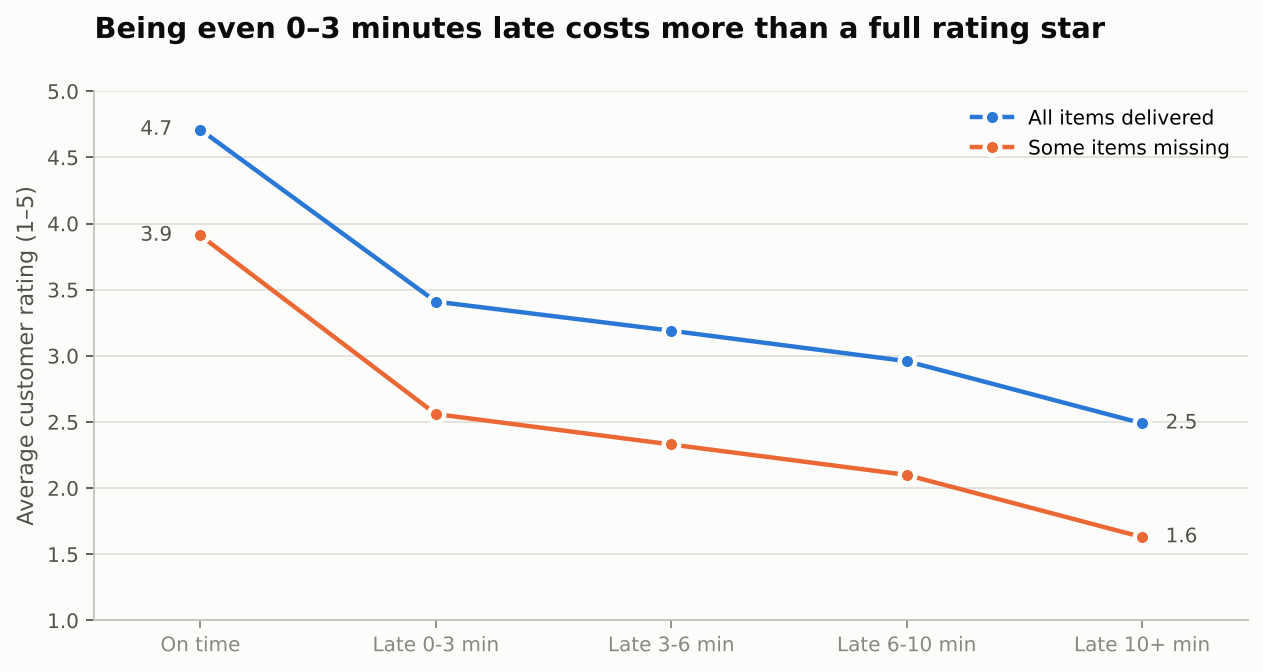

In [22]:
Image(FIG / "09_rating_vs_lateness.png", width=700)

In [23]:
pd.Series(m["revenue_impact"])

aov_inr                                        312.70
repeat_30d_on_time_pct                          68.30
repeat_30d_late_pct                             58.70
repeat_gap_pp                                    9.60
orders_lost_per_late_first_order_30d             0.28
gmv_lost_per_1000_late_first_orders_inr      89104.00
stockout_lost_revenue_6m_inr               2686661.00
stockout_lost_revenue_per_month_inr         447777.00
icecream_small_freezer_lost_inr              97775.00
slow_delivery_cancellations_6m                6868.00
slow_delivery_cancel_gmv_6m_inr            2138112.00
dtype: float64

## 7. Stockouts and baskets

In [24]:
so = pd.read_csv(P / "stockouts.csv")
so.groupby("category").lost_revenue_inr.sum().sort_values(ascending=False)

category
Ice Cream & Frozen     433955.0
Staples                377694.0
Fruits & Vegetables    374764.0
Dairy & Bread          338963.0
Beverages              230015.0
Personal Care          210630.0
Snacks                 185040.0
Household              180473.0
Instant Food           179869.0
Baby Care              158445.0
Health & OTC            16813.0
Name: lost_revenue_inr, dtype: float64

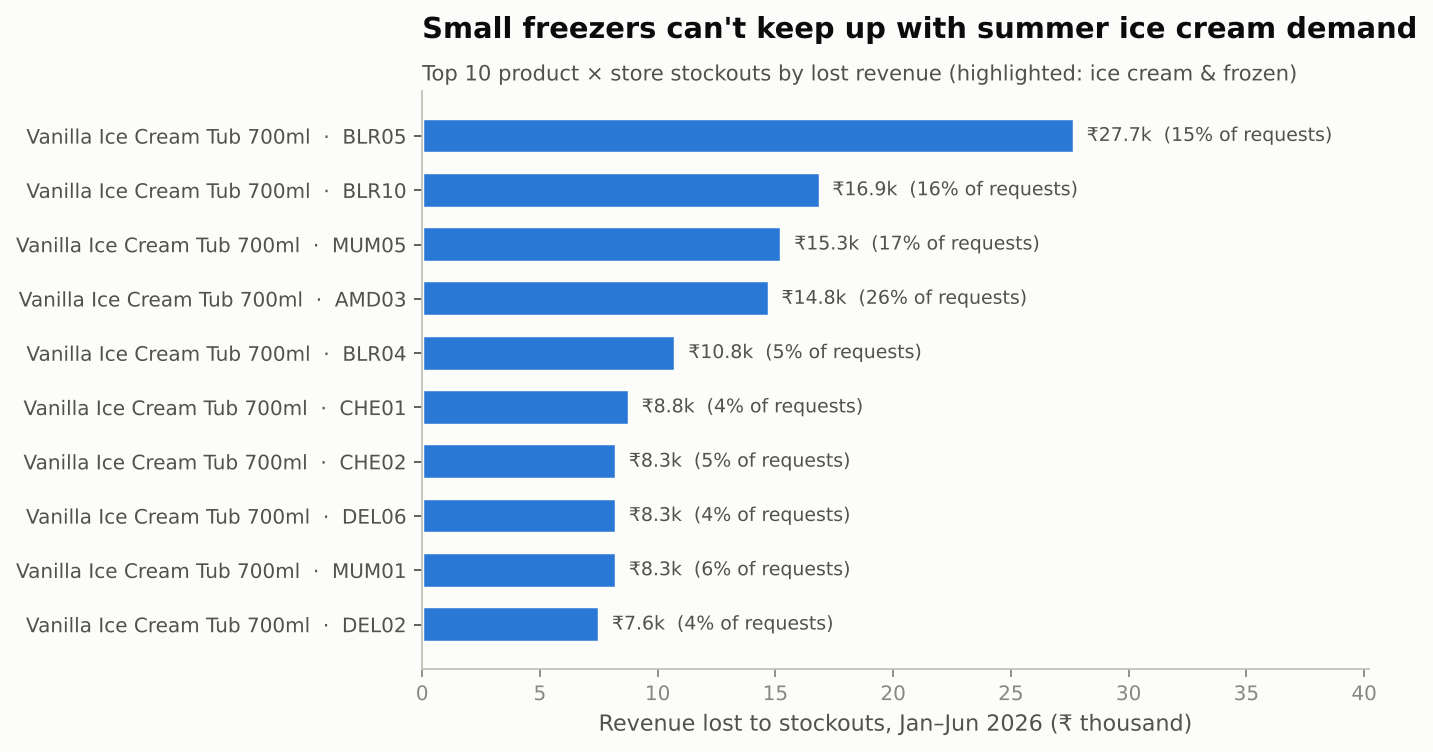

In [25]:
Image(FIG / "10_stockout_lost_revenue.png", width=760)

In [26]:
pd.read_csv(P / "basket_rules.csv").head(12)

,if_customer_buys,they_also_buy,support,confidence,lift,orders_with_both
0,Baby Wipes (72 pcs),Diapers Medium (20 pcs),0.015,0.548,15.322,5594
1,Sugar 1kg,Basmati Rice 1kg,0.008,0.287,10.077,2983
2,Chocolate Ice Cream Cone + Kulfi Stick,Vanilla Ice Cream Tub 700ml,0.010,0.620,8.521,3729
3,Cup Noodles + Tomato Ketchup 500g,Instant Noodles Masala (4 pack),0.010,0.777,7.541,3729
4,Cup Noodles + Frozen Paratha (5 pcs),Instant Noodles Masala (4 pack),0.010,0.771,7.476,3729
5,Frozen Paratha (5 pcs) + Tomato Ketchup 500g,Instant Noodles Masala (4 pack),0.009,0.771,7.475,3356
6,Dishwash Bar (3 pcs),Liquid Detergent 1L,0.010,0.290,7.326,3729
7,Chocolate Ice Cream Cone,Vanilla Ice Cream Tub 700ml,0.028,0.524,7.211,10442
8,Apple Shimla (4 pcs),Banana (6 pcs),0.014,0.457,6.669,5221
9,Kulfi Stick,Chocolate Ice Cream Cone,0.017,0.349,6.470,6340


## 8. Where to open new stores
Every neighbourhood where at least 40% of orders travel more than 3.5 km is scored as a site: re-route every order
that would be closer to it, scale travel time by the new distance and re-apply the ETA tiers.

In [27]:
pd.read_csv(P / "expansion_candidates.csv")[["rank","city_name","candidate_site_near","orders_reassigned_per_day","avg_distance_now_km","avg_distance_new_km","late_pct_now","late_pct_new","late_avoided_per_day"]]

,rank,city_name,candidate_site_near,orders_reassigned_per_day,avg_distance_now_km,avg_distance_new_km,late_pct_now,late_pct_new,late_avoided_per_day
0,1,Delhi NCR,Sohna Road,18.7,6.25,2.25,78.7,16.4,11.7
1,2,Bengaluru,Kasavanahalli,32.3,4.65,1.56,47.4,13.8,10.9
2,3,Mumbai,Ghodbunder Road,13.2,6.03,1.31,85.5,15.3,9.2
3,4,Delhi NCR,Noida Extension,12.1,6.63,1.08,85.0,13.2,8.7
4,5,Mumbai,Bhandup West,11.8,6.27,2.17,91.1,26.9,7.6
5,6,Hyderabad,Financial District,26.3,4.85,1.56,41.3,13.2,7.4
6,7,Chennai,Sholinganallur,11.9,6.07,1.10,61.9,13.3,5.8
7,8,Pune,Wagholi,6.5,7.69,1.08,94.1,13.2,5.3
8,9,Kolkata,New Town,10.5,5.42,1.12,65.0,17.6,5.0
9,10,Pune,Hadapsar,8.3,6.07,1.17,74.6,14.2,5.0


## 9. The action plan
Every diagnosed problem gets a simulated fix, ranked by late deliveries prevented per day.

In [28]:
plan = pd.read_csv(P / "action_plan.csv")
print(f"{len(plan)} fixes prevent {plan.late_avoided_per_day.sum():.0f} of {m['late_orders_per_day_now']:.0f} late orders a day")
plan[["priority","type","city_name","where","effort","late_pct_now","late_pct_after","late_avoided_per_day"]].head(12)

21 fixes prevent 165 of 562 late orders a day


,priority,type,city_name,where,effort,late_pct_now,late_pct_after,late_avoided_per_day
0,1,Riders,Bengaluru,HSR Layout (BLR03),"+22 rider-hours a day, mostly 18:00, 19:00, 20...",60.5,13.1,29.6
1,2,New store,Delhi NCR,New site near Sohna Road,"One new site, about 3 months to launch",78.7,16.4,11.7
2,3,Riders,Bengaluru,Whitefield (BLR07),"+12 rider-hours a day, mostly 9:00, 10:00, 18:...",40.0,15.7,11.4
3,4,New store,Bengaluru,New site near Kasavanahalli,"One new site, about 3 months to launch",47.4,13.8,10.9
4,5,Riders,Hyderabad,Madhapur (HYD02),"+11 rider-hours a day, mostly 9:00, 10:00, 21:...",28.8,3.8,9.6
5,6,New store,Mumbai,New site near Ghodbunder Road,"One new site, about 3 months to launch",85.5,15.3,9.2
6,7,Picking,Bengaluru,Electronic City (BLR10),Cut picking from 4.8 to 2.8 min an order,43.0,19.7,8.7
7,8,New store,Delhi NCR,New site near Noida Extension,"One new site, about 3 months to launch",85.0,13.2,8.7
8,9,Picking,Mumbai,Dadar (MUM05),Cut picking from 4.5 to 2.8 min an order,48.7,24.4,8.5
9,10,New store,Mumbai,New site near Bhandup West,"One new site, about 3 months to launch",91.1,26.9,7.6


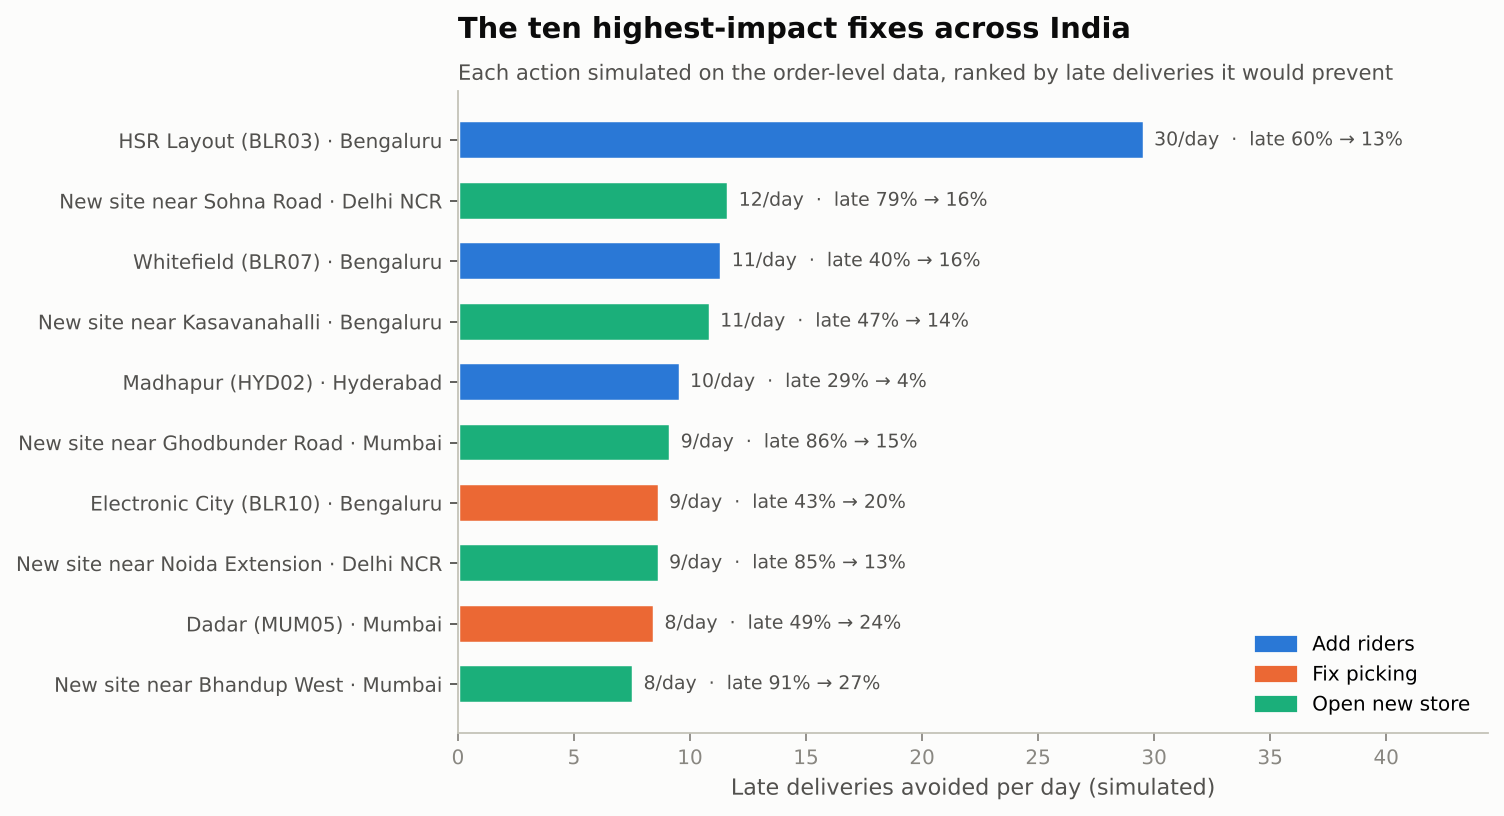

In [29]:
Image(FIG / "12_action_plan.png", width=820)

**Caveats.** The data is simulated, so the exact numbers illustrate the method rather than a real company. The
simulations hold everything else constant (for example, a new store picks and dispatches at today's network
speed), and the retention comparison is observational: customers with late first orders may differ in other ways.